# 4. Makine Öğrenmesi Modellerinin Eğitimi ve Karşılaştırılması

Bu bölümde **NASA C-MAPSS (`FD001`)** veri seti için hazırlanmış `train_fe.csv`, `val_fe.csv`, `test_fe.csv` ve `selected_features.json` kullanılarak `RUL_capped125` hedefi üzerinde dört model eğitilir ve karşılaştırılır:

- **Sızıntısız Ayrım:** `val_fe.csv` içindeki motorlar (`unit`) eğitim verisinden çıkarılır; ölçekleme (`StandardScaler` + `RobustScaler`) yalnızca eğitim verisine (`X_tr`) uygulanır.
- **Ezberleme Kontrolü:** Her model için `Train`, `Validation` ve `Test (Son Döngü)` metrikleri birlikte yazdırılır; ağaç/boosting modellerinde derinlik ve alt örnekleme sınırları ile ezberleme (`overfitting`) engellenir.
- **Tüm Döngülerde Doğruluk (%):** `0–125` döngü ölçeğine göre `(1 - MAE / 125) * 100` formülüyle genel yüzde doğruluk ve `R² (%)` gösterilir.

## 4.1 Linear Regression (Baseline)

Doğrusal ilişkileri modelleyen temel başlangıç (`baseline`) modelidir. Diğer modellerin test performansı üzerine ne kadar katkı sağladığını görmek için referans noktası oluşturur.

Linear Regression (Baseline) eğitiliyor...
--- Linear Regression Sonuçları ---
Train      -> RMSE: 21.03 | MAE: 17.21 | Doğruluk: %86.23
Test (Son) -> RMSE: 20.43 | MAE: 16.24 | R2: %74.00 | Doğruluk: %87.00
Validation -> RMSE: 19.78 | MAE: 15.96 | R2: %77.51 | Doğruluk: %87.23
Ezberleme  -> Test - Train RMSE: -0.59 döngü (Dengeli (Ezberleme yok))


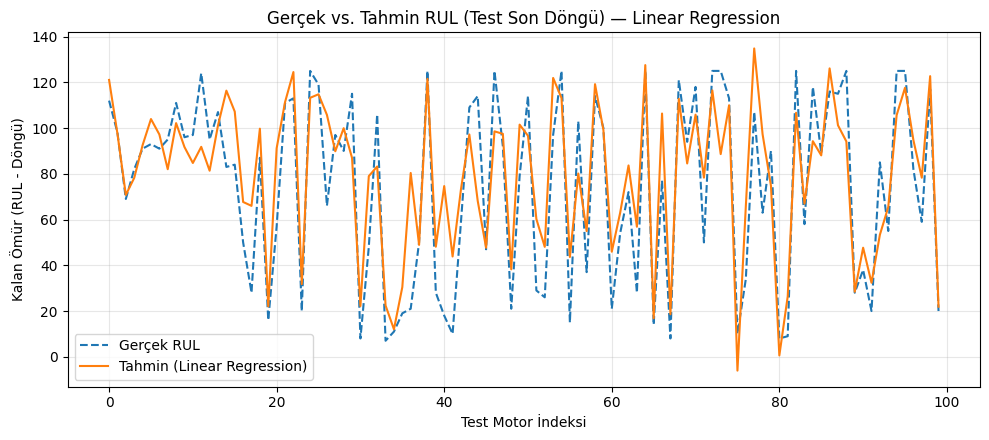

In [26]:
import json
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler, StandardScaler

TARGET_COL = "RUL_capped125"
RUL_CAP = 125.0

# 1) Verileri ve seçili özellikleri yükle
base_dir = Path.cwd()
project_root = (
    base_dir.parent
    if base_dir.name == "notebooks" and (base_dir.parent / "artifacts").exists()
    else base_dir
)
artifacts_dir = project_root / "artifacts"

train_fe = pd.read_csv(artifacts_dir / "train_fe.csv")
val_fe = pd.read_csv(artifacts_dir / "val_fe.csv")
test_fe = pd.read_csv(artifacts_dir / "test_fe.csv")

with open(
    artifacts_dir / "selected_features.json", "r", encoding="utf-8"
) as f:
  selected_features = json.load(f)["selected_features"]

# 2) Motor (unit) bazlı sızıntısız eğitim / validation ayrımı
val_units = set(val_fe["unit"].unique())
train_only_df = train_fe[~train_fe["unit"].isin(val_units)].copy()
assert set(train_only_df["unit"]).isdisjoint(
    val_units
), "Veri sızıntısı: Train ve Val arasında ortak motor var!"

X_tr = train_only_df[selected_features]
y_tr = train_only_df[TARGET_COL]

X_val = val_fe[selected_features]
y_val = val_fe[TARGET_COL]

# 3) Test son döngü (last cycle) verisi
data_dir = next(
    (
        p
        for p in [project_root / "data", Path("data"), Path("../data")]
        if (p / "RUL_FD001.txt").exists()
    ),
    None,
)
assert data_dir is not None, "RUL_FD001.txt bulunamadı! data/ klasörünü kontrol et."

test_last = test_fe.sort_values("cycle").groupby("unit", as_index=False).last()
X_test_last = test_last[selected_features]
y_true_raw = pd.read_csv(
    data_dir / "RUL_FD001.txt", sep=r"\s+", header=None, names=["RUL"]
)["RUL"]
y_test_true = np.minimum(y_true_raw.values, RUL_CAP)

# 4) Ölçekleyici (yalnızca X_tr üzerinde fit edilir)
robust_cols = [
    c for c in selected_features if c.endswith("_diff") or "_roll_std_" in c
]
standard_cols = [c for c in selected_features if c not in robust_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ("std", StandardScaler(), standard_cols),
        ("rob", RobustScaler(), robust_cols),
    ],
    remainder="drop",
)

results_summary = []


def evaluate_model(model, model_name):
  model.fit(X_tr, y_tr)

  # Train (Ezberleme kontrolü)
  tr_pred = model.predict(X_tr)
  tr_rmse = float(np.sqrt(mean_squared_error(y_tr, tr_pred)))
  tr_mae = float(mean_absolute_error(y_tr, tr_pred))
  tr_acc = max(0.0, (1.0 - tr_mae / RUL_CAP) * 100.0)

  # Test Son Döngü (Ana karşılaştırma)
  test_pred = model.predict(X_test_last)
  test_rmse = float(np.sqrt(mean_squared_error(y_test_true, test_pred)))
  test_mae = float(mean_absolute_error(y_test_true, test_pred))
  test_r2 = float(r2_score(y_test_true, test_pred))
  test_acc = max(0.0, (1.0 - test_mae / RUL_CAP) * 100.0)

  # Validation (İyileştirme aşaması için referans)
  val_pred = model.predict(X_val)
  val_rmse = float(np.sqrt(mean_squared_error(y_val, val_pred)))
  val_mae = float(mean_absolute_error(y_val, val_pred))
  val_r2 = float(r2_score(y_val, val_pred))
  val_acc = max(0.0, (1.0 - val_mae / RUL_CAP) * 100.0)

  rmse_gap = test_rmse - tr_rmse
  if rmse_gap <= 4.0:
    overfit_durum = "Dengeli (Ezberleme yok)"
  elif rmse_gap <= 8.0:
    overfit_durum = "Hafif Fark (Kontrollü)"
  else:
    overfit_durum = "Ezberleme Riski Yüksek"

  print(f"--- {model_name} Sonuçları ---")
  print(
      f"Train      -> RMSE: {tr_rmse:.2f} | MAE: {tr_mae:.2f} | Doğruluk:"
      f" %{tr_acc:.2f}"
  )
  print(
      f"Test (Son) -> RMSE: {test_rmse:.2f} | MAE: {test_mae:.2f} | R2:"
      f" %{test_r2*100:.2f} | Doğruluk: %{test_acc:.2f}"
  )
  print(
      f"Validation -> RMSE: {val_rmse:.2f} | MAE: {val_mae:.2f} | R2:"
      f" %{val_r2*100:.2f} | Doğruluk: %{val_acc:.2f}"
  )
  print(
      f"Ezberleme  -> Test - Train RMSE: {rmse_gap:+.2f} döngü ({overfit_durum})"
  )

  row = {
      "Model": model_name,
      "Test RMSE": round(test_rmse, 2),
      "Test Doğruluk (%)": round(test_acc, 2),
      "Test R2 (%)": round(test_r2 * 100, 2),
      "Train RMSE": round(tr_rmse, 2),
      "Val RMSE": round(val_rmse, 2),
      "Val Doğruluk (%)": round(val_acc, 2),
      "Ezberleme": overfit_durum,
  }

  plt.figure(figsize=(10, 4.5))
  plt.plot(y_test_true, label="Gerçek RUL", linestyle="--")
  plt.plot(test_pred, label=f"Tahmin ({model_name})")
  plt.title(f"Gerçek vs. Tahmin RUL (Test Son Döngü) — {model_name}")
  plt.xlabel("Test Motor İndeksi")
  plt.ylabel("Kalan Ömür (RUL - Döngü)")
  plt.legend()
  plt.grid(True, alpha=0.3)
  plt.tight_layout()
  plt.show()

  non_empty = [r for r in results_summary if r["Model"] != model_name]
  results_summary[:] = non_empty + [row]
  return test_pred


lr_model = Pipeline([("prep", preprocessor), ("model", LinearRegression())])
print("Linear Regression (Baseline) eğitiliyor...")
_ = evaluate_model(lr_model, "Linear Regression")

## 4.2 SVR (Support Vector Regressor)

Doğrusal olmayan sensör-RUL ilişkilerini `RBF` çekirdeği ile öğrenen modeldir. Ölçeklemeye duyarlı olduğu için eğitim verisine göre fit edilmiş ölçekleyici pipeline'ı ile çalıştırılır.

SVR eğitiliyor...
--- SVR Sonuçları ---
Train      -> RMSE: 17.23 | MAE: 10.94 | Doğruluk: %91.25
Test (Son) -> RMSE: 19.36 | MAE: 13.29 | R2: %76.67 | Doğruluk: %89.37
Validation -> RMSE: 16.93 | MAE: 11.70 | R2: %83.52 | Doğruluk: %90.64
Ezberleme  -> Test - Train RMSE: +2.13 döngü (Dengeli (Ezberleme yok))


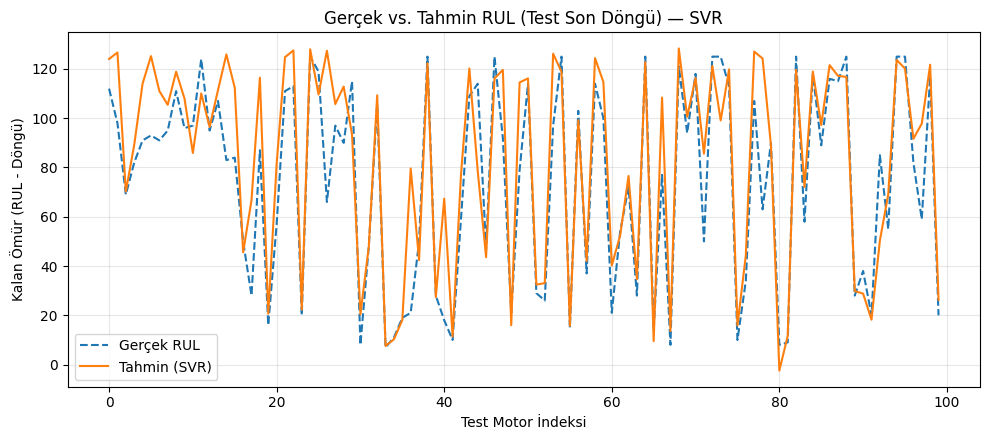

In [36]:
from sklearn.svm import SVR

svr_model = Pipeline(
    [("prep", preprocessor), ("model", SVR(kernel="rbf", C=10.0, epsilon=0.1))]
)
print("SVR eğitiliyor...")
_ = evaluate_model(svr_model, "SVR")

## 4.3 Random Forest Regressor
Doğrusal olmayan sensör bozulma örüntülerini yakalamak ve aşırı öğrenmeyi (overfitting) kontrol altında tutmak amacıyla derinliği sınırlandırılmış (`max_depth=12`, `min_samples_leaf=5`, `max_features="sqrt"`) 200 karar ağacından oluşan Random Forest modeli eğitilerek değerlendirilmiştir.

Random Forest Regressor eğitiliyor...
--- Random Forest Sonuçları ---
Train      -> RMSE: 12.76 | MAE: 9.13 | Doğruluk: %92.70
Test (Son) -> RMSE: 18.19 | MAE: 12.99 | R2: %79.39 | Doğruluk: %89.61
Validation -> RMSE: 16.28 | MAE: 11.71 | R2: %84.77 | Doğruluk: %90.64
Ezberleme  -> Test - Train RMSE: +5.43 döngü (Hafif Fark (Kontrollü))


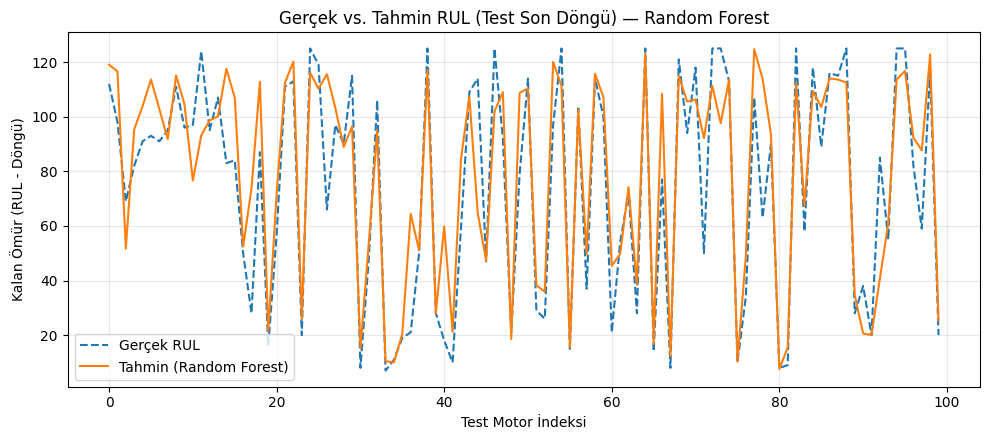

In [37]:
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ("prep", preprocessor),
    (
        "model",
        RandomForestRegressor(
            n_estimators=200,
            max_depth=12,
            min_samples_split=10,
            min_samples_leaf=5,
            max_features="sqrt",
            random_state=42,
            n_jobs=-1,
        ),
    ),
])

print("Random Forest Regressor eğitiliyor...")
rf_test_pred = evaluate_model(rf_model, "Random Forest")

## 4.4 XGBoost Regression

### Modelin Amacı ve Veri Bölme Yöntemi

Bu bölümde, NASA C-MAPSS FD001 veri setindeki motorların kalan kullanım ömrünü (RUL) tahmin etmek amacıyla XGBoost Regression algoritması kullanılmıştır.

Veri bölme işlemi **motor bazlı Hold-Out yöntemiyle** gerçekleştirilmiştir. Toplam 100 eğitim motorunun 80'i (%80) eğitim, 20'si (%20) doğrulama için ayrılmıştır.

Aynı motora ait kayıtların iki grupta bulunması engellenerek veri sızıntısı riski azaltılmıştır. Ayrıca 100 bağımsız test motoru, modelin son performansını değerlendirmek için kullanılmıştır.

Modelin başarısını ölçmek için **MAE, RMSE ve R²** metrikleri kullanılmıştır. Hiperparametre seçimi doğrulama (validation) verisindeki RMSE değerine göre yapılmıştır.

### XGBoost Hiperparametre Optimizasyonu

In [27]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_squared_error
import numpy as np
import pandas as pd

parametreler = [
    {"n_estimators": 100, "max_depth": 4, "learning_rate": 0.1},
    {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.1},
    {"n_estimators": 100, "max_depth": 3, "learning_rate": 0.1},
    {"n_estimators": 200, "max_depth": 4, "learning_rate": 0.05}
]

sonuclar = []

for i, p in enumerate(parametreler, start=1):
    model = XGBRegressor(
        **p,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_tr, y_tr)

    train_tahmin = model.predict(X_tr)
    val_tahmin = model.predict(X_val)

    train_rmse = np.sqrt(mean_squared_error(y_tr, train_tahmin))
    val_rmse = np.sqrt(mean_squared_error(y_val, val_tahmin))

    sonuclar.append({
        "Deneme": i,
        "n_estimators": p["n_estimators"],
        "max_depth": p["max_depth"],
        "learning_rate": p["learning_rate"],
        "Train RMSE": round(train_rmse, 2),
        "Validation RMSE": round(val_rmse, 2)
    })

xgb_sonuclar = pd.DataFrame(sonuclar)

display(xgb_sonuclar)

,Deneme,n_estimators,max_depth,learning_rate,Train RMSE,Validation RMSE
0,1,100,4,0.10,14.89,16.22
1,2,200,4,0.10,13.37,16.36
2,3,100,3,0.10,16.33,16.37
3,4,200,4,0.05,14.88,16.16


In [28]:
# En düşük Validation RMSE değerine sahip denemeyi bul
en_iyi_satir = xgb_sonuclar.loc[
    xgb_sonuclar["Validation RMSE"].idxmin()
]

print("--- En İyi XGBoost Parametreleri ---")
print("Ağaç sayısı:", int(en_iyi_satir["n_estimators"]))
print("Ağaç derinliği:", int(en_iyi_satir["max_depth"]))
print("Öğrenme hızı:", en_iyi_satir["learning_rate"])
print("Validation RMSE:", en_iyi_satir["Validation RMSE"])

--- En İyi XGBoost Parametreleri ---
Ağaç sayısı: 200
Ağaç derinliği: 4
Öğrenme hızı: 0.05
Validation RMSE: 16.16


In [29]:
# Validation sonucuna göre seçilen XGBoost modeli

selected_xgb_model = XGBRegressor(
    n_estimators=int(en_iyi_satir["n_estimators"]),
    max_depth=int(en_iyi_satir["max_depth"]),
    learning_rate=float(en_iyi_satir["learning_rate"]),
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

selected_xgb_model.fit(X_tr, y_tr)

print("En iyi XGBoost modeli eğitildi!")

En iyi XGBoost modeli eğitildi!


In [30]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd


xgb_train_pred = selected_xgb_model.predict(X_tr)
xgb_val_pred = selected_xgb_model.predict(X_val)
xgb_test_pred = selected_xgb_model.predict(X_test_last)


def xgb_metrikler(gercek, tahmin):
    return {
        "MAE": mean_absolute_error(gercek, tahmin),
        "RMSE": np.sqrt(mean_squared_error(gercek, tahmin)),
        "R²": r2_score(gercek, tahmin)
    }


xgb_performans = pd.DataFrame({
    "Train": xgb_metrikler(y_tr, xgb_train_pred),
    "Validation": xgb_metrikler(y_val, xgb_val_pred),
    "Test": xgb_metrikler(y_test_true, xgb_test_pred)
}).T

display(xgb_performans.round(4))

,MAE,RMSE,R²
Train,10.7513,14.8847,0.8724
Validation,11.6437,16.1572,0.8500
Test,12.9453,18.2453,0.7927


--- XGBoost Sonuçları ---
Train      -> RMSE: 14.88 | MAE: 10.75 | Doğruluk: %91.40
Test (Son) -> RMSE: 18.25 | MAE: 12.95 | R2: %79.27 | Doğruluk: %89.64
Validation -> RMSE: 16.16 | MAE: 11.64 | R2: %85.00 | Doğruluk: %90.69
Ezberleme  -> Test - Train RMSE: +3.36 döngü (Dengeli (Ezberleme yok))


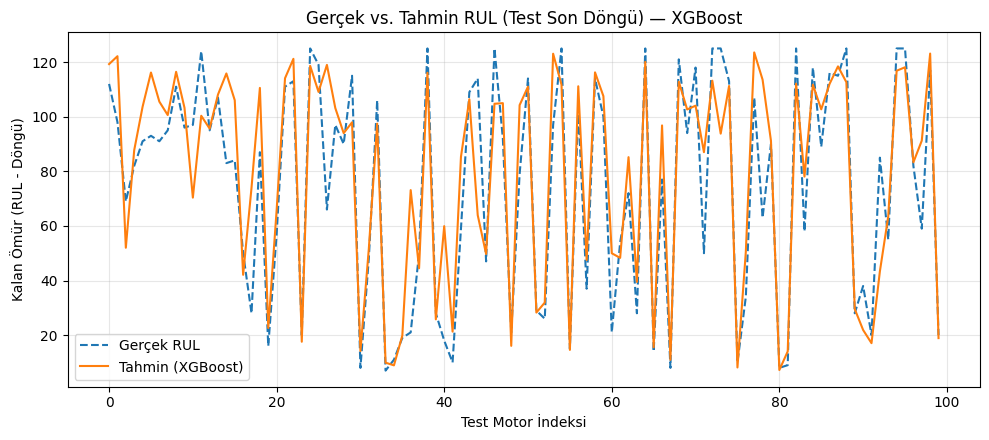

In [39]:
xgb_test_pred = evaluate_model(
    selected_xgb_model,
    "XGBoost"
)

### XGBoost Sonuçlarının Değerlendirilmesi

NASA C-MAPSS FD001 veri setinde motorların kalan kullanım ömrünü (RUL) tahmin etmek için XGBoost Regression kullanılmıştır.

**Hiperparametre optimizasyonu:** Dört farklı hiperparametre kombinasyonu denenmiştir. En düşük Validation RMSE değeri 16.16 ile dördüncü denemede elde edilmiştir. Seçilen modelde `n_estimators=200`, `max_depth=4` ve `learning_rate=0.05` kullanılmıştır.

**Overfitting değerlendirmesi:** Seçilen modelin Train RMSE değeri 14.88, Validation RMSE değeri 16.16'dır. Aradaki fark 1.28 döngüdür. Bu sonuçlar belirgin bir aşırı öğrenme işareti göstermemektedir. Ağaç derinliği ve öğrenme hızının farklı değerleri denenerek modelin karmaşıklığı kontrol edilmiştir.

**Test sonuçları:** Bağımsız test motorlarında MAE 12.95, RMSE 18.25 ve R² 0.7927 elde edilmiştir. Test verisi hiperparametre seçiminde kullanılmamıştır.

Sonuç olarak seçilen XGBoost modeli, eğitimde görmediği motorların kalan kullanım ömrünü tahmin etmede başarılı sonuçlar vermiştir. Model seçimi doğrulama verisiyle, son değerlendirme ise bağımsız test verisiyle yapılmıştır.

## 4.5 Modellerin Karşılaştırılması

Modeller **Test (Son Döngü) RMSE** değerine göre sıralanmıştır (`Test RMSE` ne kadar düşükse hata o kadar düşüktür). En iyi çıkan model bir sonraki adımda **Validation (`val_fe.csv`)** üzerinden iyileştirilecektir.


NİHAİ MODEL KARŞILAŞTIRMASI (TEST SON DÖNGÜ)


,Model,Test RMSE,Test Doğruluk (%),Test R2 (%),Train RMSE,Val RMSE,Val Doğruluk (%),Ezberleme
0,Random Forest,18.190000,89.610000,79.390000,12.760000,16.280000,90.640000,Hafif Fark (Kontrollü)
1,XGBoost,18.250000,89.640000,79.270000,14.880000,16.160000,90.690000,Dengeli (Ezberleme yok)
2,SVR,19.360000,89.370000,76.670000,17.230000,16.930000,90.640000,Dengeli (Ezberleme yok)
3,Linear Regression,20.430000,87.000000,74.000000,21.030000,19.780000,87.230000,Dengeli (Ezberleme yok)


/tmp/ipykernel_5291/3938567553.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x="Test RMSE", y="Model", data=results_df, palette="viridis")


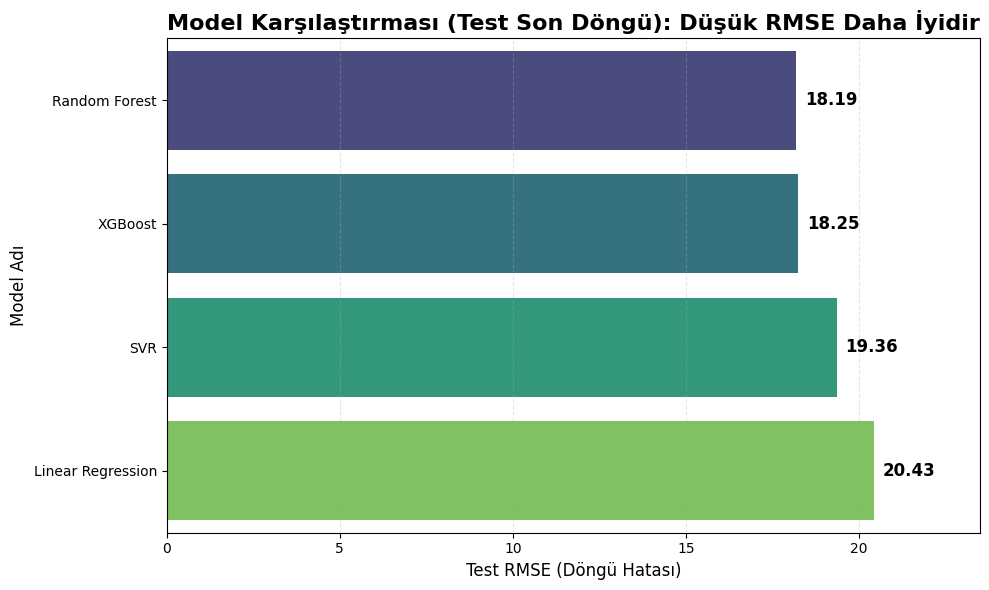

En İyi Model (Test): Random Forest


In [40]:
results_df = (
    pd.DataFrame(results_summary)
    .sort_values(by="Test RMSE")
    .reset_index(drop=True)
)

print("\nNİHAİ MODEL KARŞILAŞTIRMASI (TEST SON DÖNGÜ)")
display(
    results_df.style.background_gradient(cmap="Greens_r", subset=["Test RMSE"])
)

plt.figure(figsize=(10, 6))
sns.barplot(x="Test RMSE", y="Model", data=results_df, palette="viridis")
plt.title(
    "Model Karşılaştırması (Test Son Döngü): Düşük RMSE Daha İyidir",
    fontsize=16,
    fontweight="bold",
)
plt.xlabel("Test RMSE (Döngü Hatası)", fontsize=12)
plt.ylabel("Model Adı", fontsize=12)

for index, value in enumerate(results_df["Test RMSE"]):
  plt.text(
      value + 0.25, index, f"{value:.2f}", va="center", fontsize=12, fontweight="bold"
  )

plt.xlim(0, max(results_df["Test RMSE"]) * 1.15)
plt.grid(axis="x", linestyle="--", alpha=0.3)
plt.tight_layout()
plt.show()

print(f"En İyi Model (Test): {results_df.iloc[0]['Model']}")